# Multivariate Analysis

# Objective
Explore relationships among several variables, identify strong/weak/negative correlations, potential multicollinearity, and feature interactions. Examples use Telco Customer Churn.

# Setup and load data
This notebook uses the IBM Telco Customer Churn dataset. Put WA_Fn-UseC_-Telco-Customer-Churn.csv beside this notebook, or change DATA_PATH below.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)
n = 60
age = np.random.randint(22, 56, n)
experience = np.clip(age - 22 + np.random.randint(-4, 5, n), 0, None)
salary = 25000 + experience * 2600 + np.random.normal(0, 8500, n)
monthly_spend = 5000 + salary * 0.18 + np.random.normal(0, 4200, n)
performance = np.clip(np.random.normal(70, 12, n), 35, 100)
department = np.random.choice(['IT', 'HR', 'Finance'], n)
purchased = np.where(monthly_spend > np.median(monthly_spend), 'Yes', 'No')
df = pd.DataFrame({
    'Age': age, 'Experience': experience, 'Salary': salary.round(0),
    'Monthly_Spend': monthly_spend.round(0), 'Performance_Score': performance.round(1),
    'Department': department, 'Purchased': purchased
})
print(df.head())

   Age  Experience   Salary  Monthly_Spend  Performance_Score Department  \
0   50          28  98625.0        23805.0               76.9    Finance   
1   36          17  77433.0        20393.0               83.6         HR   
2   29          11  47633.0        10718.0               81.4         HR   
3   42          24  84615.0        21206.0               77.8    Finance   
4   40          14  58067.0        16683.0               66.2         HR   

  Purchased  
0       Yes  
1       Yes  
2        No  
3       Yes  
4        No  


# 1. Correlation Matrix
# Definition
A correlation matrix is a table showing correlation coefficients for pairs of numerical columns. Values range from -1 to +1. Positive values indicate variables tend to increase together, while negative values indicate opposite movement. Values near zero suggest little linear relationship.

# Business Example
An HR team compares age, work experience, and salary to understand how the measures move together. A matrix gives a quick overview of which pairs appear related. The team can investigate whether strongly related inputs are redundant.

# AI/ML Use
Correlation screening helps identify potentially redundant numerical inputs before model training. It can also suggest relationships worth exploring in feature engineering. Correlation does not prove that one feature causes another.

# Python Example

In [10]:
numeric_df = df.select_dtypes(include='number')
corr = numeric_df.corr()
print(corr.round(2))

                    Age  Experience  Salary  Monthly_Spend  Performance_Score
Age                1.00        0.96    0.93           0.66              -0.21
Experience         0.96        1.00    0.95           0.65              -0.18
Salary             0.93        0.95    1.00           0.73              -0.20
Monthly_Spend      0.66        0.65    0.73           1.00              -0.23
Performance_Score -0.21       -0.18   -0.20          -0.23               1.00


# Explanation
Each cell contains the Pearson correlation for two numerical features. Look for large positive or negative values away from the diagonal. A strong value is a signal for further investigation, not proof of causation.

# 2. Heatmap
Definition
A heatmap represents values using colors. For correlation analysis, color intensity helps show the direction and strength of relationships. It makes a correlation matrix easier to scan. A heatmap is a visualization of the numbers, not a different statistical test.

# Business Example
A manager wants to compare several salary-related measures without reading a large table. A heatmap highlights the strongest relationships visually. This helps the manager decide which combinations need closer review.

# AI/ML Use
In EDA, a correlation heatmap can flag feature pairs that may cause multicollinearity. It helps teams choose which variables to inspect before modeling. The actual correlations should still be checked numerically.

# Python Example

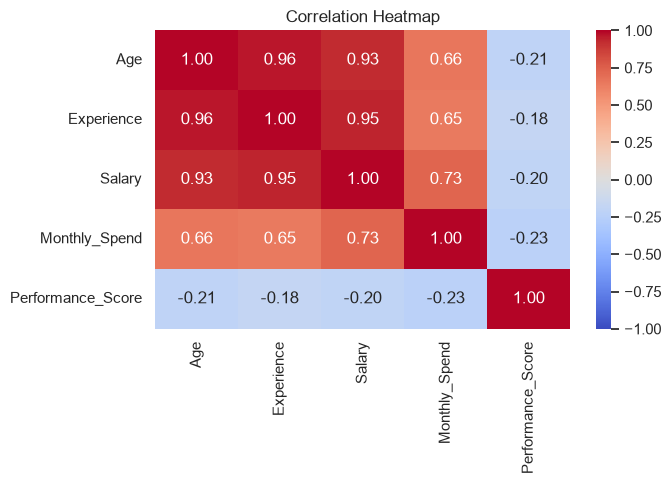

In [11]:
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

# Explanation
Warm and cool colors distinguish positive and negative correlations. Numbers in the cells show the exact approximate values. Strongly colored off-diagonal cells deserve attention during feature selection.

# 3. Pair Plot
# Definition
A pair plot displays scatter plots for multiple pairs of numerical features. It also shows each variable’s distribution on the diagonal. This allows several relationships to be compared at once. It is especially helpful for spotting clusters, trends, and unusual points.

# Business Example
An analyst compares Age, Salary, and Monthly_Spend for employees. The pair plot reveals whether larger salaries generally go with higher spending. It may also show a few unusual employees who need investigation.

# AI/ML Use
Pair plots help identify nonlinear-looking trends, potential outliers, and groups before building models. They are useful when the number of selected features is small. Large datasets or too many columns can make the plot slow or cluttered.

# Python Example

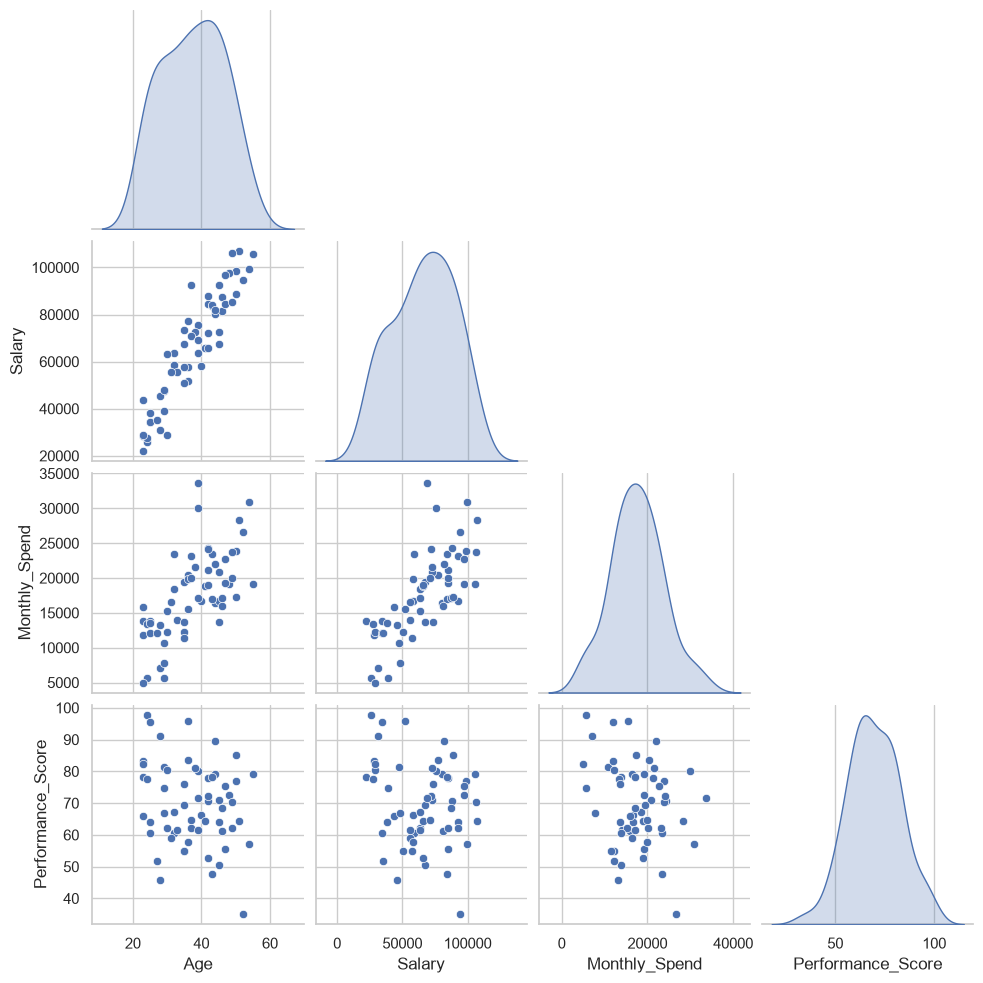

In [12]:
sns.pairplot(df[['Age', 'Salary', 'Monthly_Spend', 'Performance_Score']], corner=True, diag_kind='kde')
plt.show()

# Explanation
Each off-diagonal panel compares two variables; diagonal panels show individual distributions. An upward pattern suggests positive association. Scattered clouds suggest a weaker relationship.

# 4. Multiple Feature Relationships
Definition
Multiple feature relationships examine how three or more variables relate to each other. A pattern seen between two features can change when a third feature is considered. Color, size, and grouping can help represent extra variables in one plot. This provides more context than a single pairwise comparison.

# Business Example
A business compares employee age and salary while separating departments by color. It can see whether salary patterns differ between IT, HR, and Finance. The added department information makes the comparison more meaningful.

# AI/ML Use
ML performance can depend on combinations of predictors rather than isolated variables. Exploring several features together may reveal groups or conditional patterns. These insights can guide model selection and feature creation.

# Python Example

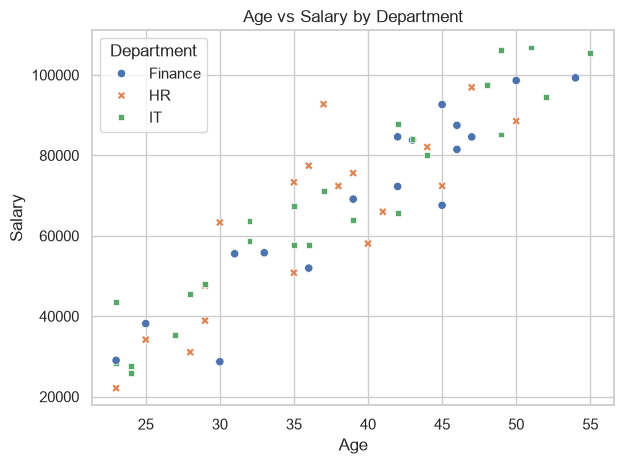

In [13]:
sns.scatterplot(data=df, x='Age', y='Salary', hue='Department', style='Department')
plt.title('Age vs Salary by Department')
plt.tight_layout()
plt.show()

# Explanation
The x-axis is Age and the y-axis is Salary. Each color and marker represents a department. Compare the overall trend and check whether department groups occupy different areas of the plot.

# 5. Feature Interactions
Definition
A feature interaction occurs when the relationship between one input and an outcome depends on another input. For example, experience might be associated with salary differently across departments. An interaction feature combines inputs to represent such effects. Not every interaction improves a model, so it should be validated.

# Business Example
A company finds that extra years of experience are rewarded differently in different departments. Looking at experience alone hides this difference. Comparing departments can show where the effect appears stronger or weaker.

# AI/ML Use
Some models can learn interactions automatically, while linear models may benefit from explicitly created interaction terms. Interactions can improve predictions when they capture real patterns. Their usefulness must be checked with validation data.

# Python Example

   Experience Department  Experience_x_IT
0          28    Finance                0
1          17         HR                0
2          11         HR                0
3          24    Finance                0
4          14         HR                0
5          26         IT               26
6          12         IT               12
7          14         IT               14
8          26    Finance                0
9          19         HR                0


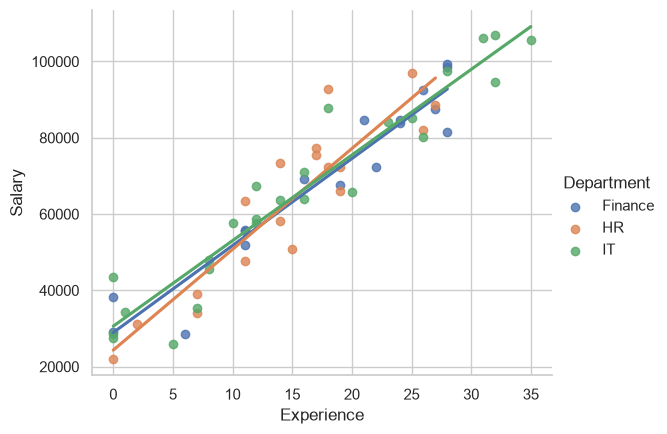

In [14]:
df['Experience_x_IT'] = df['Experience'] * (df['Department'] == 'IT').astype(int)
print(df[['Experience', 'Department', 'Experience_x_IT']].head(10))
sns.lmplot(data=df, x='Experience', y='Salary', hue='Department', ci=None, height=4.5, aspect=1.3)
plt.show()

# Explanation
The new column keeps Experience for IT employees and becomes zero for other departments. The chart shows separate fitted trends by department. Differences in slope may suggest an interaction, but this small synthetic example is not conclusive.

# 6. Numerical Feature Relationships
Definition
Numerical feature relationships focus on how quantitative variables vary together. Scatter plots and correlations are common ways to examine these patterns. Relationships may be positive, negative, weak, strong, or nonlinear. Different plots can reveal patterns a single statistic misses.

# Business Example
A retailer checks whether higher customer income is linked to higher spending. It also looks for customers whose spending is unusual for their income. This can inform customer segmentation and marketing decisions.

# AI/ML Use
Numerical relationship analysis helps spot redundancy, potential predictors, and outliers. It can guide scaling, transformations, and feature selection. Always consider data leakage and use training data for preprocessing decisions.

# Python Example

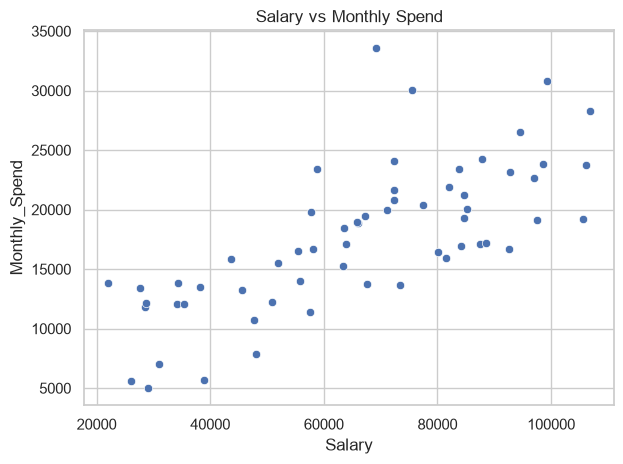

Correlation: 0.73


In [15]:
sns.scatterplot(data=df, x='Salary', y='Monthly_Spend')
plt.title('Salary vs Monthly Spend')
plt.tight_layout()
plt.show()
print('Correlation:', round(df['Salary'].corr(df['Monthly_Spend']), 2))

# Explanation
The scatter plot shows how spending changes across salary levels. The printed correlation summarizes the linear association. A positive value indicates higher salaries tend to accompany higher spending in this sample.

# 7. Strong Correlations
Definition
Strong correlation means two numerical variables have a close linear relationship. A correlation coefficient (r) near +1 indicates they increase together, while one near -1 indicates they move in opposite directions. For this practice notebook, an absolute correlation of 0.70 or above is considered strong.

# Business Example
An HR analyst may notice that employees with more experience generally earn higher salaries. Comparing these two columns helps understand whether they change together.

# AI/ML Use
Strongly correlated inputs can contain overlapping information. An ML engineer may review them during feature selection, although correlation alone does not mean a feature should be removed.

# Python Example

In [16]:
correlations = df.select_dtypes(include='number').corr()
pairs = correlations.where(np.triu(np.ones(correlations.shape), k=1).astype(bool)).stack()
strong = pairs[pairs.abs() >= 0.70]
print(strong.round(2) if not strong.empty else 'No strong correlations found')

Age         Experience       0.96
            Salary           0.93
Experience  Salary           0.95
Salary      Monthly_Spend    0.73
dtype: float64


# Explanation
The code displays pairs with |r| ≥ 0.70. Positive values show features moving together, and negative values show opposite movement. These are sample-data findings, not proof of cause and effect.

# correlations = df.select_dtypes(include='number').corr()
pairs = correlations.where(np.triu(np.ones(correlations.shape), k=1).astype(bool)).stack()
weak = pairs[pairs.abs() < 0.30]
print(weak.round(2) if not weak.empty else 'No weak correlations found')8. Weak Correlations
# Definition
Weak correlation means two numerical features have little linear association. Their correlation coefficient is close to zero. Here we use |r| below 0.30 as a simple guideline, but a weak Pearson correlation does not rule out nonlinear relationships.

# Business Example
A company may find that employee performance scores do not change consistently with employee age. The two measurements could show a weak linear relationship.

# AI/ML Use
Weakly correlated features may still provide useful independent information to a model. Check other patterns before dropping a feature based only on a low correlation.

# Python Example

In [18]:
correlations = df.select_dtypes(include='number').corr()
pairs = correlations.where(np.triu(np.ones(correlations.shape), k=1).astype(bool)).stack()
weak = pairs[pairs.abs() < 0.30]
print(weak.round(2) if not weak.empty else 'No weak correlations found')

Age                Performance_Score   -0.21
Experience         Performance_Score   -0.18
Salary             Performance_Score   -0.20
Monthly_Spend      Performance_Score   -0.23
                   Experience_x_IT      0.25
Performance_Score  Experience_x_IT     -0.21
dtype: float64


# Explanation
The code prints pairs with |r| below 0.30. Values near zero suggest little linear trend in this sample. A scatter plot can help check whether a curved relationship exists.

# 9. Negative Correlations
# Definition
Negative correlation occurs when one numerical variable tends to decrease as another increases. Its correlation coefficient is below zero, with values closer to -1 showing a stronger negative linear relationship. Even a small negative number indicates direction, not necessarily a meaningful relationship.

# Business Example
A store may observe that higher product prices are associated with fewer units sold. This would be a negative relationship if the trend is consistent.

# AI/ML Use
Negative correlations help ML engineers understand feature directions and investigate potentially useful predictors. A negative coefficient does not mean the feature is bad for the model.

# Python Example

In [19]:
correlations = df.select_dtypes(include='number').corr()
pairs = correlations.where(np.triu(np.ones(correlations.shape), k=1).astype(bool)).stack()
negative = pairs[pairs < 0]
print(negative.round(2) if not negative.empty else 'No negative correlations found')

Age                Performance_Score   -0.21
Experience         Performance_Score   -0.18
Salary             Performance_Score   -0.20
Monthly_Spend      Performance_Score   -0.23
Performance_Score  Experience_x_IT     -0.21
dtype: float64


# Explanation
The code lists all negatively correlated pairs. Check the size of each coefficient: a value near zero is a weak negative association. This synthetic dataset may have only weak negative correlations.

# 10. Potential Multicollinearity
# Definition
Multicollinearity occurs when predictor variables are strongly related to one another. It can make regression coefficients unstable and harder to interpret. High pairwise correlation is a useful warning sign, but does not fully diagnose multicollinearity among several predictors.

# Business Example
A salary prediction dataset may contain both Age and Experience. Because these often rise together, they could provide overlapping information.

# AI/ML Use
For linear regression, strongly related predictors can make coefficient interpretation unreliable. An engineer can examine variance inflation factors (VIF), feature importance, or validation results before deciding what to keep.

# Python Example

In [20]:
features = df[['Age', 'Experience', 'Salary', 'Monthly_Spend', 'Performance_Score']]
feature_corr = features.corr()
upper = feature_corr.where(np.triu(np.ones(feature_corr.shape), k=1).astype(bool))
flagged = upper.stack()
flagged = flagged[flagged.abs() >= 0.80]
print(flagged.round(2) if not flagged.empty else 'No highly correlated predictor pairs found')

Age         Experience    0.96
            Salary        0.93
Experience  Salary        0.95
dtype: float64


# Explanation
The code flags numerical predictor pairs with |r| ≥ 0.80. These pairs deserve further checking, but the result alone does not prove a harmful multicollinearity problem.

# 11. Interesting Feature Relationships
# Definition
Interesting feature relationships are patterns that stand out when several variables are compared. They may include trends, differences between groups, or unusual observations. Such findings help decide which questions to investigate next.

# Business Example
A business may observe that spending increases with salary, while performance scores show little connection to spending. These patterns can guide customer or employee analysis.

# AI/ML Use
Feature relationships may inspire feature engineering, transformations, or new model hypotheses. Any useful-looking pattern should be checked on held-out data before being relied on.

# Python Example

In [21]:
print('Salary vs Monthly_Spend:', round(df['Salary'].corr(df['Monthly_Spend']), 2))
print('Age vs Experience:', round(df['Age'].corr(df['Experience']), 2))
print('Performance_Score vs Salary:', round(df['Performance_Score'].corr(df['Salary']), 2))

Salary vs Monthly_Spend: 0.73
Age vs Experience: 0.96
Performance_Score vs Salary: -0.2


# Explanation
The three values summarize possible relationships in the sample. Compare their magnitudes to see which pairs have stronger or weaker linear associations. These results are illustrative and should not be generalized to real employees.